# Harness check

The harness in [harness/](../harness/) on a 20-row dry run per system, before the full runs.

This notebook:

1. runs both systems on the same 20 rows, the way `just run` does, and shows what a run writes,
2. stops and reruns them, to show that a run continues where it stopped,
3. builds the results table and checks it: the same columns for both systems, one row per product, system and question, a probability for every option,
4. counts the states Laya truncates on our side, and checks that count against Laya itself,
5. shows that a failed request stays in the results instead of being dropped,
6. takes a first look at the answers, to check they line up with the ground truth labels,
7. puts the speed of the dry run next to what the full runs will take.

The dry run uses the first 20 rows of the calibration split.
Nothing here is a reported number, and the evaluation split stays unseen until the full run.

Before running: start Laya with `just laya` in a terminal, and put the Jev key in `.env` as `JEV_API_KEY`.
Section 4 also uses a second, non-strict Laya, started with `just laya 8766 0`; without it, that check is skipped.
Running the whole notebook sends 28 products to Jev, a fraction of a cent.

In [1]:
import dataclasses
import json
import os
import shutil
import sys
import warnings
from pathlib import Path

import duckdb
import httpx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# The notebooks live in notebooks/; every path below is from the project root
os.chdir(next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()))

assert Path(sys.prefix).resolve() == Path(".venv").resolve(), (
    f"The kernel runs {sys.executable}, not this project's .venv. Start Jupyter with `just lab`."
)

# Laya's tokenizer code imports tqdm, which warns that ipywidgets is missing; no progress bar is shown here
warnings.filterwarnings("ignore", message="IProgress not found")

from harness.questions import OPTIONS, QUESTIONS, truth_of
from harness.runs import LAYA_VERSION, ROOT, RUNS, SAMPLE, SYSTEMS as ALL_SYSTEMS, build, final_lines, read_log, run
from harness.truncation import Truncation

# The published Laya against Jev; laya-ft, the Laya fine-tuned on the calibration split, comes after training
SYSTEMS = {name: ALL_SYSTEMS[name] for name in ("laya", "jev")}
RUN = "dry-run"
SPLIT, ROWS = "calibration", 20
LAYA_VERBOSE_URL = "http://127.0.0.1:8766"  # `just laya 8766 0`: the same Laya, reporting truncation
FULL_RUN = 100_000
JEV_USD_PER_MILLION_TOKENS = 0.042

con = duckdb.connect()

In [2]:
def sql(query: str) -> pd.DataFrame:
    return con.sql(query).df()


def show(df: pd.DataFrame, precision: int = 2) -> None:
    display(df.style.hide(axis="index").format(thousands=",", precision=precision))


def mark(ok: bool, detail: str = "") -> str:
    return f"{'✓' if ok else '✗'} {detail}".strip()


INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
EMPHASIS, GRAY = "#2a78d6", "#b5b3aa"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 120,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 10.5,
    "axes.titlecolor": INK_2,
    "axes.titlepad": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": MUTED,
})

## 1. The dry run

`run(system, run, split=..., limit=...)` is what `just run` calls.
It reads the rows from `data/sample.parquet` in id order, pins the model version, and sends the states with the questions from [request.json](../request.json):

- Laya through `/v1/systemone/batch`, 64 states per call (the 20 rows fit in one), sorted by length into passes of 16, after one warm-up call;
- Jev through `/v1/systemone`, one state per request, 4 requests in flight and at most 600 per minute, half the published limit.

A request that fails is retried with exponential backoff, and a `429` waits as long as its `retry-after` asks.

In [3]:
shutil.rmtree(RUNS / RUN, ignore_errors=True)  # the dry run starts clean; only this notebook writes it

for system in SYSTEMS:
    await run(system, RUN, split=SPLIT, limit=ROWS)

laya: 20 of 20 products to send to laya 0.4.18, english@7b928d8


laya: 20 of 20 products, 0 failed, 4.8 products/s, 4 s so far, 0 s to go


jev: 20 of 20 products to send to jev-1.14.0


jev: 20 of 20 products, 0 failed, 9.3 products/s, 2 s so far, 0 s to go


### What a run writes

A run is a folder under `data/runs/`, with two files per system:

- the raw log, `<system>.jsonl`: one line per product and attempt, holding the raw response, or the error when there is none;
- the manifest, `<system>.json`: what the run is pinned to, and every invocation with its timings.

In [4]:
def describe(path: Path) -> str:
    if path.suffix == ".jsonl":
        return f"raw log, {len(read_log(path))} lines"
    return "manifest"


show(pd.DataFrame([
    {"file": str(path.relative_to(ROOT)), "what": describe(path), "bytes": path.stat().st_size}
    for path in sorted((RUNS / RUN).iterdir())
]))

file,what,bytes
data/runs/dry-run/jev.json,manifest,"2,589"
data/runs/dry-run/jev.jsonl,"raw log, 20 lines","21,151"
data/runs/dry-run/laya.json,manifest,"3,147"
data/runs/dry-run/laya.jsonl,"raw log, 20 lines","24,171"


What each system's run is pinned to.
Laya's `model_version` combines the release `just laya` serves with the checkpoint commit from `/health`, because Laya's own `model` field always says `laya-rl-agent`.
Jev is pinned by name, and the harness stops if a response ever comes back from another version.

In [5]:
pinned = {system: json.loads((RUNS / RUN / f"{system}.json").read_text())["pinned"] for system in SYSTEMS}
show(pd.DataFrame(pinned).map(str).rename_axis("pinned").reset_index())

pinned,laya,jev
system,laya,jev
base_url,http://127.0.0.1:8765,https://api.typesafe.ai
model,english,jev-1.14.0
model_version,"laya 0.4.18, english@7b928d8",jev-1.14.0
revision,7b928d828b7b0e022f929d9bd2e44165aa270148,None
checkpoint,None,None
route,/v1/systemone/batch,/v1/systemone
chunk,64,1
batch_options,"{'sort_by_length': True, 'batch_size': 16}",{}
questions_sha256,f145886e0c93fccd1dfe175e7d3481138a8a65f8b4627c443afa9cbb372478c6,f145886e0c93fccd1dfe175e7d3481138a8a65f8b4627c443afa9cbb372478c6


The first line of each raw log, without its `response`, which is the system's answer exactly as it came back (its shape is in [systems-check.ipynb](systems-check.ipynb)).
A batch call's time is shared by its products in `latency_ms`; the call itself is in `call`.

In [6]:
show(pd.DataFrame([
    {key: value for key, value in read_log(RUNS / RUN / f"{system}.jsonl")[0].items() if key != "response"}
    for system in SYSTEMS
]).map(lambda value: json.dumps(value) if isinstance(value, dict) else value), precision=1)

id,system,model_version,at,attempts,latency_ms,call,error
1,laya,"laya 0.4.18, english@7b928d8",2026-10-31T21:03:31+00:00,1,196.1,"{""route"": ""/v1/systemone/batch"", ""first_id"": 1, ""states"": 20, ""ms"": 3921.3, ""total_usage"": {""input_tokens"": 13129, ""output_tokens"": 0}}",None
1,jev,jev-1.14.0,2026-10-31T21:03:31+00:00,1,208.1,"{""route"": ""/v1/systemone"", ""states"": 1, ""ms"": 208.1}",None


## 2. A stopped run continues where it stopped

Rerunning a run sends only the products that have no response yet.
Right after a complete run, that is none.

In [7]:
for system in SYSTEMS:
    await run(system, RUN, split=SPLIT, limit=ROWS)

laya: 0 of 20 products to send to laya 0.4.18, english@7b928d8


jev: 0 of 20 products to send to jev-1.14.0


To see a real stop, cut the last 8 lines off each log, as if the run had been stopped there, and run again.
Only those 8 products are sent.

In [8]:
for system in SYSTEMS:
    log = RUNS / RUN / f"{system}.jsonl"
    log.write_text("".join(line + "\n" for line in log.read_text().splitlines()[: ROWS - 8]))

for system in SYSTEMS:
    await run(system, RUN, split=SPLIT, limit=ROWS)

laya: 8 of 20 products to send to laya 0.4.18, english@7b928d8


laya: 8 of 8 products, 0 failed, 4.7 products/s, 2 s so far, 0 s to go


jev: 8 of 20 products to send to jev-1.14.0


jev: 8 of 8 products, 0 failed, 9.2 products/s, 1 s so far, 0 s to go


Every invocation is recorded in the manifest.

In [9]:
show(pd.DataFrame([
    {
        "system": system,
        "invocation": number,
        "products": invocation["products"],
        "to send": invocation["to_send"],
        "failed": invocation["failed"],
        "seconds": invocation["seconds"],
    }
    for system in SYSTEMS
    for number, invocation in enumerate(json.loads((RUNS / RUN / f"{system}.json").read_text())["invocations"], 1)
]), precision=1)

system,invocation,products,to send,failed,seconds
laya,1,20,20,0,4.2
laya,2,20,0,0,0.0
laya,3,20,8,0,1.7
jev,1,20,20,0,2.1
jev,2,20,0,0,0.0
jev,3,20,8,0,0.9


A run is pinned to its model version, route, batch settings, questions and rows.
Rerunning it with any of them changed is refused, so one run never mixes two setups:

In [10]:
try:
    await run("laya", RUN, split=SPLIT, limit=50)
except RuntimeError as refusal:
    print(refusal)

data/runs/dry-run/laya.json is pinned to another limit; start a new run name


## 3. The results table

`build(run)` turns the raw logs into `results.parquet`, one row per product, system and question.
No request is sent: everything comes from the logs.

Both systems fill the same columns.
`truncated` and `state_tokens_dropped` are Laya's only, and `error` stays empty while every request succeeds.

In [11]:
RESULTS = build(RUN)
results = f"read_parquet('{RESULTS}')"

frame = sql(f"FROM {results}")
columns = sql(f"DESCRIBE FROM {results}")[["column_name", "column_type"]]
show(pd.DataFrame({
    "column": columns.column_name,
    "type": columns.column_type,
    "Laya rows filled": frame[frame.system == "laya"].notna().sum().values,
    "Jev rows filled": frame[frame.system == "jev"].notna().sum().values,
}))

column,type,Laya rows filled,Jev rows filled
id,BIGINT,60,60
split,VARCHAR,60,60
system,VARCHAR,60,60
model_version,VARCHAR,60,60
question,VARCHAR,60,60
answer,VARCHAR,60,60
probs,"MAP(VARCHAR, DOUBLE)",60,60
latency_ms,DOUBLE,60,60
input_tokens,BIGINT,60,60
truncated,BOOLEAN,60,0


Product 1, both systems:

In [12]:
show(sql(f"""
    SELECT question, system, answer, probs, latency_ms, input_tokens, truncated
    FROM {results} WHERE id = 1 ORDER BY question, system DESC
"""), precision=1)

question,system,answer,probs,latency_ms,input_tokens,truncated
food_group,laya,milk and dairy products,"{'alcoholic beverages': 0.0034, 'beverages': 0.0079, 'cereals and potatoes': 0.0037, 'composite foods': 0.0035, 'fats and sauces': 0.0083, 'fish, meat and eggs': 0.0009, 'fruits and vegetables': 0.0039, 'milk and dairy products': 0.9612, 'salty snacks': 0.0027, 'sugary snacks': 0.0045}",196.1,671,False
food_group,jev,milk and dairy products,"{'alcoholic beverages': 0.0, 'beverages': 0.0, 'cereals and potatoes': 0.0, 'composite foods': 0.0, 'fats and sauces': 0.0, 'fish, meat and eggs': 0.0, 'fruits and vegetables': 0.0, 'milk and dairy products': 1.0, 'salty snacks': 0.0, 'sugary snacks': 0.0}",208.1,866,
nutriscore,laya,B,"{'A': 0.4402, 'B': 0.4506, 'C': 0.0862, 'D': 0.0165, 'E': 0.0065}",196.1,671,False
nutriscore,jev,C,"{'A': 0.01, 'B': 0.2, 'C': 0.6, 'D': 0.19, 'E': 0.0}",208.1,866,
ultra_processed,laya,yes,"{'yes': 0.8545, 'no': 0.1455}",196.1,671,False
ultra_processed,jev,yes,"{'yes': 0.72, 'no': 0.28}",208.1,866,


### Checks

The notebook stops here if one of them fails.

In [13]:
raw = {system: final_lines(RUNS / RUN / f"{system}.jsonl") for system in SYSTEMS}


def checks(system: str) -> dict[str, str]:
    rows = frame[frame.system == system]
    versions = rows.model_version.unique()
    pin = f"laya {LAYA_VERSION}, " if system == "laya" else SYSTEMS["jev"].model
    keys_ok = all(list(probs) == OPTIONS[question] for probs, question in zip(rows.probs, rows.question))
    off = max(abs(sum(probs.values()) - 1) for probs in rows.probs)
    tolerance = 0.011 if system == "jev" else 0.0011  # Jev rounds to 2 decimals, Laya to 4
    most_likely = all(probs[answer] == max(probs.values()) for probs, answer in zip(rows.probs, rows.answer))
    food = rows[rows.question == "food_group"]
    own_choice = sum(raw[system][id]["response"]["answers"]["food_group"]["choice"] == answer
                     for id, answer in zip(food.id, food.answer))
    per_product = rows.drop_duplicates("id")
    truncated = rows.truncated.dropna()
    return {
        "one row per product and question": mark(
            len(rows) == ROWS * len(QUESTIONS) and not rows.duplicated(["id", "question"]).any(), f"{len(rows)} rows"),
        "no failed request": mark(rows.error.isna().all(), f"{rows.error.notna().sum()} failed"),
        "one pinned model version": mark(len(versions) == 1 and versions[0].startswith(pin), versions[0]),
        "a probability for every option, in option order": mark(keys_ok),
        "probabilities sum to 1": mark(off <= tolerance, f"off by at most {off:.4f}"),
        "the answer is the most likely option": mark(most_likely),
        "food_group answer is the system's own choice": mark(own_choice == ROWS, f"{own_choice} of {ROWS}"),
        "input tokens reported": mark(per_product.input_tokens.notna().all(),
                                      f"median {per_product.input_tokens.median():,.0f} per product"),
        "truncation counted": mark(len(truncated) == len(rows), f"{int(truncated.sum())} cut") if system == "laya" else "n/a",
    }


report = pd.DataFrame({"Laya": checks("laya"), "Jev": checks("jev")}).rename_axis("check").reset_index()
show(report)
assert not report[["Laya", "Jev"]].map(lambda cell: cell.startswith("✗")).any().any(), "a check failed"

check,Laya,Jev
one row per product and question,✓ 60 rows,✓ 60 rows
no failed request,✓ 0 failed,✓ 0 failed
one pinned model version,"✓ laya 0.4.18, english@7b928d8",✓ jev-1.14.0
"a probability for every option, in option order",✓,✓
probabilities sum to 1,✓ off by at most 0.0002,✓ off by at most 0.0000
the answer is the most likely option,✓,✓
food_group answer is the system's own choice,✓ 20 of 20,✓ 20 of 20
input tokens reported,✓ median 659 per product,✓ median 864 per product
truncation counted,✓ 0 cut,n/a


## 4. Truncation, counted on our side

The English Laya reads 512 tokens.
Each question's head, its instructions and one span per option, goes in first, and the state gets the room that is left; the rest of the state is cut.
So the room depends on the question: `food_group` has ten options and leaves the least.

The strict server (`LAYA_JEV_STRICT=1`) matches Jev's response shape, and with it drops the `usage` fields that report truncation.
The harness therefore repeats Laya's own computation, with Laya's code (`laya` 0.4.18 is installed in this project too) and the checkpoint's own tokenizer.

In [14]:
counter = Truncation(pinned["laya"]["revision"], LAYA_VERSION)
rooms = {question: counter.room(QUESTIONS[question]) for question in QUESTIONS}

show(pd.DataFrame([
    {"question": question, "options": len(OPTIONS[question]), "state tokens it leaves": rooms[question],
     "of max_len": counter.max_len}
    for question in QUESTIONS
]))

question,options,state tokens it leaves,of max_len
food_group,10,329,512
ultra_processed,2,445,512
nutriscore,5,436,512


### How many evaluation states are cut

Truncation depends only on the input, not on an answer, so it can be counted on the evaluation split before the full run.

In [15]:
evaluation = sql(f"SELECT id, state, ultra_processed FROM read_parquet('{SAMPLE}') WHERE split = 'evaluation'")
evaluation["tokens"] = counter.state_tokens(evaluation.state.tolist())

cut_rows = []
for question, room in rooms.items():
    cut = evaluation.tokens > room
    cut_rows.append({
        "question": question,
        "room": room,
        "states cut": cut.sum(),
        "share cut": f"{cut.mean():.1%}",
        "tokens dropped, median": (evaluation.tokens[cut] - room).median(),
        "NOVA 4 among the cut": f"{evaluation.ultra_processed[cut].mean():.1%}",
    })
show(pd.DataFrame(cut_rows), precision=0)
print(f"NOVA 4 among all {len(evaluation):,} evaluation states: {evaluation.ultra_processed.mean():.1%}")

question,room,states cut,share cut,"tokens dropped, median",NOVA 4 among the cut
food_group,329,"2,512",2.8%,64,99.2%
ultra_processed,445,728,0.8%,78,99.7%
nutriscore,436,798,0.9%,77,99.6%


NOVA 4 among all 90,000 evaluation states: 67.0%


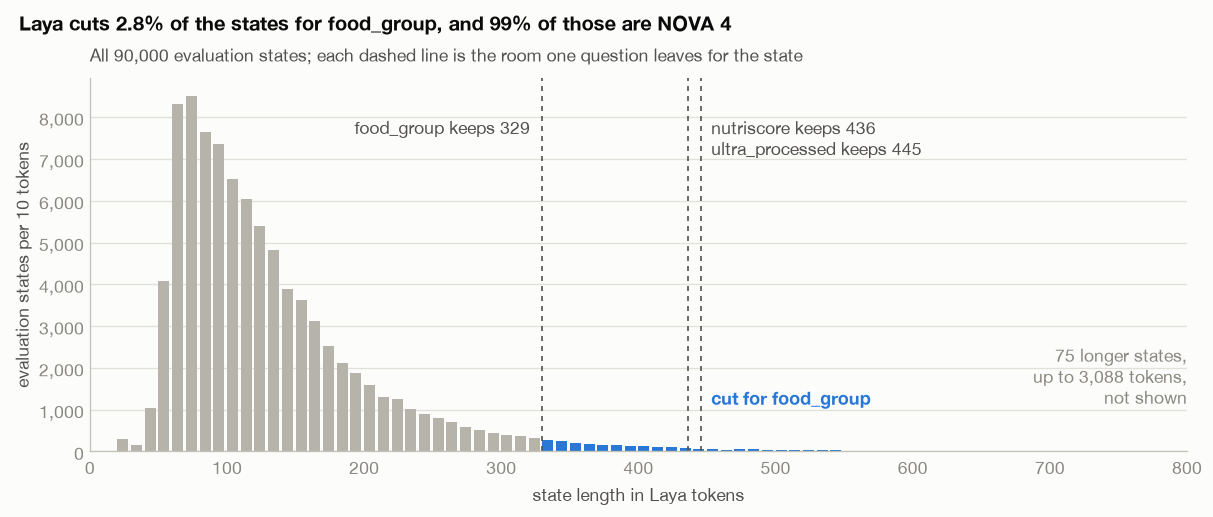

In [16]:
LIMIT = 800  # tokens; the few longer states are counted in a note instead of stretching the axis
edges = np.arange(0, LIMIT + 10, 10)  # integer lengths, so [320, 330) still fits next to food_group
counts, _ = np.histogram(evaluation.tokens[evaluation.tokens < LIMIT], bins=edges)
colors = [EMPHASIS if left > rooms["food_group"] else GRAY for left in edges[:-1]]

fig, ax = plt.subplots(figsize=(10, 4.2), layout="constrained")
ax.bar(edges[:-1], counts, width=8, align="edge", color=colors)
top = counts.max()
for question, room in rooms.items():
    ax.axvline(room + 0.5, color=INK_2, linewidth=1, linestyle=(0, (3, 3)))
ax.text(rooms["food_group"] - 8, top * 0.94, f"food_group keeps {rooms['food_group']}", color=INK_2, va="top", ha="right")
others = sorted((room, question) for question, room in rooms.items() if question != "food_group")
right_of_lines = others[-1][0] + 8
ax.text(right_of_lines, top * 0.94, "\n".join(f"{question} keeps {room}" for room, question in others),
        color=INK_2, va="top")
ax.text(right_of_lines, top * 0.12, "cut for food_group", color=EMPHASIS, va="bottom", fontweight="bold")
longer = evaluation.tokens >= LIMIT
ax.text(LIMIT, top * 0.30, f"{longer.sum()} longer states,\nup to {evaluation.tokens.max():,} tokens,\nnot shown",
        color=MUTED, ha="right", va="top")

ax.set_xlim(0, LIMIT)
ax.set_xlabel("state length in Laya tokens")
ax.set_ylabel("evaluation states per 10 tokens")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}")
ax.tick_params(length=0)
ax.grid(axis="x", visible=False)

food_cut = evaluation.tokens > rooms["food_group"]
fig.suptitle(
    f"Laya cuts {food_cut.mean():.1%} of the states for food_group, "
    f"and {evaluation.ultra_processed[food_cut].mean():.0%} of those are NOVA 4",
    x=0.01, ha="left", fontweight="bold", fontsize=12,
)
ax.set_title(f"All {len(evaluation):,} evaluation states; each dashed line is the room one question leaves for the state")
plt.show()

The long states are long ingredient lists, and long ingredient lists are NOVA 4, so the cut lands on `ultra_processed`'s majority class.
Their additives often sit at the end of the list, which is the part Laya does not read.

### Checked against Laya itself

The count above is our own.
A second Laya, started with `just laya 8766 0`, runs the same release and checkpoint without strict mode, and reports truncation in `usage`.
It gets the calibration states right at each room's edge (one token under, at and over the room) and the four longest ones.

In [17]:
try:
    verbose_health = httpx.get(f"{LAYA_VERBOSE_URL}/health").json()
except httpx.ConnectError:
    verbose_health = None
    display(Markdown("Skipped: start the non-strict Laya with `just laya 8766 0` and run this cell again."))

if verbose_health:
    assert verbose_health["revisions"]["english"] == pinned["laya"]["revision"], "the two servers load other checkpoints"
    calibration = sql(f"SELECT id, state FROM read_parquet('{SAMPLE}') WHERE split = 'calibration' ORDER BY id")
    calibration["tokens"] = counter.state_tokens(calibration.state.tolist())
    edge_lengths = {room + step for room in rooms.values() for step in (-1, 0, 1)}
    probe = pd.concat([
        calibration[calibration.tokens.isin(edge_lengths)].groupby("tokens").head(1),
        calibration.nlargest(4, "tokens"),
    ]).sort_values("tokens")
    reply = httpx.post(f"{LAYA_VERBOSE_URL}/v1/systemone/batch", timeout=600, json={
        "model": SYSTEMS["laya"].model, "states": probe.state.tolist(), "questions": QUESTIONS,
        **SYSTEMS["laya"].batch_options,
    }).json()

    agreement = []
    for product, result in zip(probe.itertuples(), reply["results"], strict=True):
        usage = result["usage"]
        ours = ", ".join(question for question in QUESTIONS if product.tokens > rooms[question]) or "none"
        theirs = ", ".join(question for question in QUESTIONS if question in usage["truncated_questions"]) or "none"
        dropped = max(0, product.tokens - min(rooms.values()))
        agreement.append({
            "id": product.id,
            "state tokens (ours)": product.tokens,
            "state tokens (Laya)": usage["state_tokens"],
            "cut for (ours)": ours,
            "cut for (Laya)": theirs,
            "most dropped (ours)": dropped,
            "most dropped (Laya)": usage["state_tokens_dropped"],
            "agree": mark(product.tokens == usage["state_tokens"] and ours == theirs
                          and dropped == usage["state_tokens_dropped"]),
        })
    agreement = pd.DataFrame(agreement)
    show(agreement, precision=0)
    assert (agreement.agree == "✓").all(), "our truncation count disagrees with Laya's"

Skipped: start the non-strict Laya with `just laya 8766 0` and run this cell again.

## 5. A failed request stays in the results

The same Jev settings, pointed at a port where nothing listens, with 2 attempts per request instead of 6.
Every product still gets its three rows, with the error and the number of attempts, and no answer.

A rerun of the run retries the failed products, and their earlier failures stay in the raw log.
After 5 failed requests in a row a run stops, because the system is down and logging more failures helps nobody.

In [18]:
DOWN = dataclasses.replace(SYSTEMS["jev"], base_url="http://127.0.0.1:9", api_key_env=None, max_attempts=2, backoff_s=0.1)
shutil.rmtree(RUNS / "failure-check", ignore_errors=True)

await run(DOWN, "failure-check", split=SPLIT, limit=3)
show(sql(f"SELECT id, system, question, answer, attempts, error FROM '{build('failure-check')}' ORDER BY id"))
shutil.rmtree(RUNS / "failure-check")

jev: 3 of 3 products to send to jev-1.14.0


jev: 3 of 3 products, 3 failed, 5.9 products/s, 1 s so far, 0 s to go


id,system,question,answer,attempts,error
1,jev,food_group,None,2,ConnectError: All connection attempts failed
1,jev,ultra_processed,None,2,ConnectError: All connection attempts failed
1,jev,nutriscore,None,2,ConnectError: All connection attempts failed
2,jev,food_group,None,2,ConnectError: All connection attempts failed
2,jev,ultra_processed,None,2,ConnectError: All connection attempts failed
2,jev,nutriscore,None,2,ConnectError: All connection attempts failed
3,jev,food_group,None,2,ConnectError: All connection attempts failed
3,jev,ultra_processed,None,2,ConnectError: All connection attempts failed
3,jev,nutriscore,None,2,ConnectError: All connection attempts failed


## 6. A first look at the answers

This is not an accuracy: it is 20 calibration rows.
It checks that answers and ground truth use the same labels, so a right answer is counted as right.

In [19]:
truth = {
    row.id: truth_of(row.food_group, row.ultra_processed, row.nutriscore)
    for row in sql(f"SELECT * FROM read_parquet('{SAMPLE}') WHERE split = '{SPLIT}' ORDER BY id LIMIT {ROWS}").itertuples()
}
answers = frame.pivot_table(index=["id", "question"], columns="system", values="answer", aggfunc="first").reset_index()
answers["truth"] = [truth[id][question] for id, question in zip(answers.id, answers.question)]

show(pd.DataFrame([
    {
        "question": question,
        "Laya right": f"{(group.laya == group.truth).sum()} of {len(group)}",
        "Jev right": f"{(group.jev == group.truth).sum()} of {len(group)}",
        "Laya and Jev agree": f"{(group.laya == group.jev).sum()} of {len(group)}",
    }
    for question, group in answers.groupby("question", sort=False)
]))

question,Laya right,Jev right,Laya and Jev agree
food_group,13 of 20,19 of 20,13 of 20
nutriscore,5 of 20,13 of 20,3 of 20
ultra_processed,10 of 20,20 of 20,10 of 20


`food_group`, row by row:

In [20]:
names = sql(f"SELECT id, name FROM read_parquet('{SAMPLE}') WHERE split = '{SPLIT}' ORDER BY id LIMIT {ROWS}")
food = answers[answers.question == "food_group"].merge(names, on="id")
show(pd.DataFrame({
    "id": food.id,
    "product": food.name,
    "truth": food.truth,
    "Laya": [mark(answer == truth, answer) for answer, truth in zip(food.laya, food.truth)],
    "Jev": [mark(answer == truth, answer) for answer, truth in zip(food.jev, food.truth)],
}))

id,product,truth,Laya,Jev
1,Gourmet Swiss Style Yogurt,milk and dairy products,✓ milk and dairy products,✓ milk and dairy products
2,Raspberries,fruits and vegetables,✓ fruits and vegetables,✓ fruits and vegetables
3,BBLUEBRA LACKCURRANT SPO& /DE NOMADIC,milk and dairy products,✓ milk and dairy products,✓ milk and dairy products
4,Italian sausage pizza,composite foods,✗ fats and sauces,✓ composite foods
5,Sunflower and Pumpkin Soft Farmhouse,cereals and potatoes,✗ fruits and vegetables,✓ cereals and potatoes
6,Avocado Oil,fats and sauces,✓ fats and sauces,✓ fats and sauces
7,Oven Roasted Turkey Breast,"fish, meat and eggs",✗ fats and sauces,"✓ fish, meat and eggs"
8,Low moisture part skim mozzarella light string,milk and dairy products,✗ fats and sauces,✓ milk and dairy products
9,Marshmallow sandwich minis chocolate,sugary snacks,✓ sugary snacks,✓ sugary snacks
10,Le blé gourmand,cereals and potatoes,✓ cereals and potatoes,✓ cereals and potatoes


## 7. Speed: the dry run and the full run

Laya's speed is states per second of batch-call time, so the warm-up call and the gaps between calls do not count.
Jev's run time is set by the 600 requests per minute the harness allows, not by its latency.

In [21]:
laya_calls = {line["call"]["first_id"]: line["call"] for line in read_log(RUNS / RUN / "laya.jsonl") if line["response"]}
laya_per_second = sum(call["states"] for call in laya_calls.values()) / (sum(call["ms"] for call in laya_calls.values()) / 1000)

jev_lines = [line for line in final_lines(RUNS / RUN / "jev.jsonl").values() if line["response"]]
jev_ms = pd.Series([line["latency_ms"] for line in jev_lines])
jev_tokens = pd.Series([line["response"]["usage"]["input_tokens"] for line in jev_lines]).median()
jev_per_minute = SYSTEMS["jev"].per_minute

show(pd.DataFrame([
    {
        "system": "Laya",
        "dry run": f"{laya_per_second:.1f} products per second on MPS",
        f"full run of {FULL_RUN:,}": f"about {FULL_RUN / laya_per_second / 3600:.1f} hours",
        "cost": "own hardware",
    },
    {
        "system": "Jev",
        "dry run": f"{jev_ms.median():.0f} ms p50, {jev_ms.quantile(0.95):.0f} ms p95, {jev_tokens:.0f} input tokens per product",
        f"full run of {FULL_RUN:,}": f"about {FULL_RUN / jev_per_minute / 60:.1f} hours at {jev_per_minute:.0f} requests per minute",
        "cost": f"about ${FULL_RUN * jev_tokens / 1e6 * JEV_USD_PER_MILLION_TOKENS:.2f}",
    },
]))

system,dry run,"full run of 100,000",cost
Laya,5.2 products per second on MPS,about 5.3 hours,own hardware
Jev,"180 ms p50, 227 ms p95, 864 input tokens per product",about 2.8 hours at 600 requests per minute,about $3.63


## 8. The full runs

The two runs use different resources, the laptop's GPU and the network, so they can run at the same time:

```sh
just laya          # terminal 1: leave it running
just run laya      # terminal 2: stop with Ctrl-C at any time, run it again to continue
just run jev       # terminal 3: the same
just build         # once both are done: data/runs/full/results.parquet
```

Both runs go through the rows in id order, so the calibration split, which fitting Laya's temperature needs, is done first.